<div style="background: linear-gradient(135deg, #b83232 0%, #315f7d 100%); padding: 36px 40px; border-radius: 10px; color: white; margin-bottom: 20px;">
  <h1 style="color: white; margin: 0 0 8px 0; font-size: 2em;">PINN vs VPINN | Heat Transfer</h1>
  <h2 style="color: #e5eef4; margin: 0 0 12px 0; font-weight: normal; font-size: 1.25em;">1D Steady-State Conduction with Internal Heat Generation</h2>
  <p style="color: #d6e2ea; margin: 0;">Primeiro benchmark didático · Dimensional · Adam · PyTorch</p>
</div>

Este notebook reúne os dois modelos estudados para o **mesmo problema físico**.

- **PINN:** forma forte da EDO, avaliada ponto a ponto.
- **VPINN:** forma fraca, avaliada por resíduos variacionais integrais.

A intenção é manter este primeiro exemplo deliberadamente simples. Não usamos adimensionalização, L-BFGS, Fourier features, balanceamento automático de pesos, decomposição de domínio ou refinamento adaptativo.

---
# 1. Problema físico comum

Consideramos uma barra unidimensional de comprimento $L$ e condutividade térmica constante $k$, com geração volumétrica uniforme $\dot q$.

A equação governante é

$$
-\frac{d}{dx}\left(k\frac{dT}{dx}\right)=\dot q,
\qquad x\in(0,L).
$$

Como $k$ é constante,

$$
\frac{d^2T}{dx^2}+\frac{\dot q}{k}=0.
$$

As condições de contorno são

$$
T(0)=T_{\mathrm{left}}
$$

e

$$
\left.\frac{dT}{dx}\right|_{x=L}=0.
$$

A solução analítica, usada **somente para verificação**, é

$$
T(x)=T_{\mathrm{left}}+\frac{\dot q}{k}
\left(Lx-\frac{x^2}{2}\right).
$$

## 1.1 Preparação do ambiente computacional

In [ ]:
import time
import torch
import torch.nn as nn
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## 1.2 Geometria, parâmetros e solução analítica

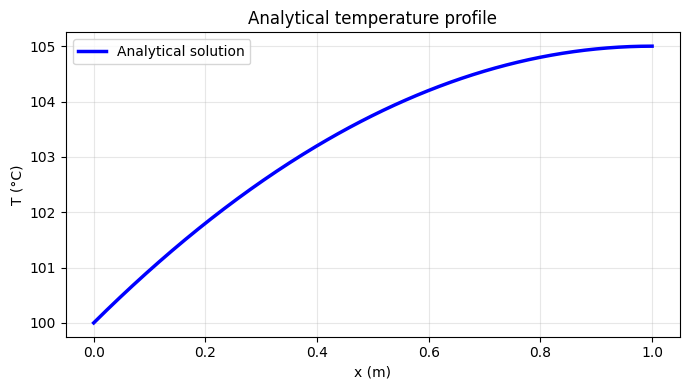

Peak temperature: 105.00 °C at x = 1.00 m


In [ ]:
L            = 1.0    # rod length (m)
k            = 1.0    # thermal conductivity (W/m·K)
q_dot        = 10.0   # volumetric heat generation (W/m^3)

T_left       = 100.0  # Dirichlet target at x=0 (°C)
dTdx_right   = 0.0    # Neumann target at x=L (K/m)

x_start = 0.0
x_end   = L


########## Solução Analítica ##########

def T_exact_fn(x):
    return T_left + (q_dot / k) * (L * x - 0.5 * x**2)

def dTdx_exact_fn(x):
    return (q_dot / k) * (L - x)

x_exact = np.linspace(x_start, x_end, 300)
T_exact = T_exact_fn(x_exact)

plt.figure(figsize=(7, 4))
plt.plot(x_exact, T_exact, "b-", lw=2.5, label="Analytical solution")
plt.xlabel("x (m)")
plt.ylabel("T (°C)")
plt.title("Analytical temperature profile")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Peak temperature: {T_exact.max():.2f} °C at x = {x_exact[np.argmax(T_exact)]:.2f} m")

---
# 2. Rede neural comum aos dois métodos

Para tornar a comparação controlada, PINN e VPINN usam a mesma arquitetura:

$$
x
\longrightarrow
[64\text{-Tanh}]_{\times 3}
\longrightarrow
\hat T(x;\theta).
$$

A diferença entre os métodos não está na rede, mas em **como a física entra na função de perda**.

In [ ]:
class FullyConnectedNN(nn.Module):
    def __init__(self, N_INPUT, N_OUTPUT, N_HIDDEN, N_LAYERS):
        super().__init__()
        activation = nn.Tanh

        self.fcs = nn.Sequential(
            nn.Linear(N_INPUT, N_HIDDEN),
            activation()
        )

        self.fch = nn.Sequential(*[
            nn.Sequential(
                nn.Linear(N_HIDDEN, N_HIDDEN),
                activation()
            )
            for _ in range(N_LAYERS - 1)
        ])

        self.fce = nn.Linear(N_HIDDEN, N_OUTPUT)

    def forward(self, x):
        x = self.fcs(x)
        x = self.fch(x)
        return self.fce(x)

---
# 3. PINN - Formulação forte

A PINN impõe a equação diferencial diretamente nos pontos de colocação.

O resíduo forte é

$$
r_{\mathrm{ODE}}(x;\theta)
=
\frac{d^2\hat T}{dx^2}
+
\frac{\dot q}{k}.
$$

A loss usada neste baseline é

$$
\mathcal L_{\mathrm{PINN}}
=
\lambda_{\mathrm{BC}}
\left(
\mathcal L_D+\mathcal L_N
\right)
+
\lambda_{\mathrm{ODE}}\mathcal L_{\mathrm{ODE}}.
$$

Aqui, tanto Dirichlet quanto Neumann são impostas explicitamente por penalidade.

## 3.1 Configuração do treinamento PINN

In [ ]:
torch.manual_seed(123)

pinn_T = FullyConnectedNN(
    N_INPUT=1,
    N_OUTPUT=1,
    N_HIDDEN=64,
    N_LAYERS=3
).to(device)

N_ODE       = 500
lambda_bc_p = 1.0
lambda_ODE  = 3.0

epochs = 8000
lr     = 1e-3

optimiser_pinn = torch.optim.Adam(pinn_T.parameters(), lr=lr)

loss_history_pinn = {
    "total": [],
    "dirichlet": [],
    "neumann": [],
    "ODE": []
}

print(f"PINN network: {sum(p.numel() for p in pinn_T.parameters())} parameters")
print(f"Collocation points: {N_ODE}")

PINN network: 8513 parameters
Collocation points: 500


## 3.2 Pontos de avaliação PINN

In [ ]:
x_bc_left_pinn = torch.tensor(
    [[x_start]],
    dtype=torch.float32,
    device=device,
    requires_grad=False
)

x_bc_right_pinn = torch.tensor(
    [[x_end]],
    dtype=torch.float32,
    device=device,
    requires_grad=True
)

x_domain = torch.linspace(
    x_start,
    x_end,
    N_ODE,
    device=device
).view(-1, 1)

x_domain.requires_grad_(True)

pass

## 3.3 Resíduos e loss PINN

In [ ]:
def compute_pinn_losses():
    # Dirichlet BC: T(0) = T_left
    T_pred_left = pinn_T(x_bc_left_pinn)
    r_D = T_pred_left - T_left
    loss_dirichlet = (r_D**2).squeeze()

    # Neumann BC: dT/dx(L) = 0
    T_pred_right = pinn_T(x_bc_right_pinn)

    dTdx_pred_right = torch.autograd.grad(
        T_pred_right,
        x_bc_right_pinn,
        torch.ones_like(T_pred_right),
        create_graph=True
    )[0]

    r_N = dTdx_pred_right - dTdx_right
    loss_neumann = (r_N**2).squeeze()

    loss_bc = loss_dirichlet + loss_neumann

    # Strong ODE residual
    T_pred_ODE = pinn_T(x_domain)

    dTdx_ODE = torch.autograd.grad(
        T_pred_ODE,
        x_domain,
        torch.ones_like(T_pred_ODE),
        create_graph=True
    )[0]

    d2Tdx2_ODE = torch.autograd.grad(
        dTdx_ODE,
        x_domain,
        torch.ones_like(dTdx_ODE),
        create_graph=True
    )[0]

    r_ODE = d2Tdx2_ODE + q_dot / k
    loss_ODE = torch.mean(r_ODE**2)

    loss = (
        lambda_bc_p * loss_bc
        + lambda_ODE * loss_ODE
    )

    return loss, loss_dirichlet, loss_neumann, loss_ODE

## 3.4 Laço de otimização PINN

In [ ]:
t0 = time.perf_counter()

for i in tqdm(range(epochs + 1), desc="Training 1D Conduction PINN"):
    optimiser_pinn.zero_grad()

    loss, loss_dirichlet, loss_neumann, loss_ODE = compute_pinn_losses()

    loss.backward()
    optimiser_pinn.step()

    loss_history_pinn["total"].append(loss.item())
    loss_history_pinn["dirichlet"].append(loss_dirichlet.item())
    loss_history_pinn["neumann"].append(loss_neumann.item())
    loss_history_pinn["ODE"].append(loss_ODE.item())

time_pinn = time.perf_counter() - t0

print("PINN training complete.")
print(f"Training time : {time_pinn:.2f} s")
print(f"Final loss    : {loss_history_pinn['total'][-1]:.3e}")

Training 1D Conduction PINN: 100%|██████████| 8001/8001 [01:16<00:00, 105.04it/s]

PINN training complete.
Training time : 76.18 s
Final loss    : 1.053e-02


## 3.5 Verificação e gráficos PINN

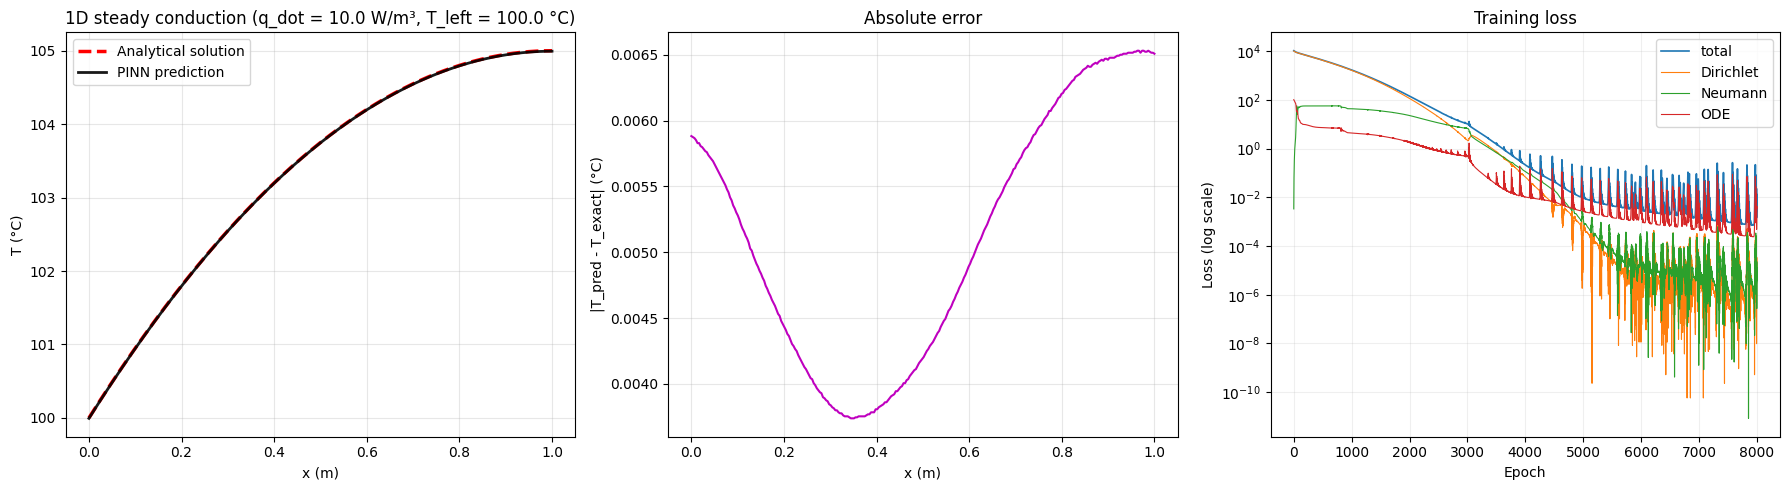

Max absolute error              : 6.5308e-03 °C
Relative L2 error (T)           : 5.0235e-05
Relative L2 error (T-T_left)    : 1.4218e-03
dT/dx at x=0  (pred / exact)    : +10.0029 / +10.0000 K/m
dT/dx at x=L  (pred / exact)    : +0.0007 / +0.0000 K/m
Heat flux at x=0 (pred / exact) : -10.0029 / -10.0000 W/m²


In [ ]:
x_test = torch.linspace(
    x_start,
    x_end,
    300,
    device=device
).view(-1, 1)

with torch.no_grad():
    T_pred_pinn = pinn_T(x_test).cpu().numpy().ravel()

x_np = x_test.cpu().numpy().ravel()
T_ref = T_exact_fn(x_np)

abs_error_pinn = np.abs(T_pred_pinn - T_ref)

max_err_pinn = np.max(abs_error_pinn)
rel_L2_pinn = np.linalg.norm(T_pred_pinn - T_ref) / np.linalg.norm(T_ref)
rel_L2_theta_pinn = (
    np.linalg.norm(T_pred_pinn - T_ref)
    / np.linalg.norm(T_ref - T_left)
)

x_ends_pinn = torch.tensor(
    [[x_start], [x_end]],
    dtype=torch.float32,
    device=device,
    requires_grad=True
)

T_ends_pinn = pinn_T(x_ends_pinn)

dTdx_ends_pinn = torch.autograd.grad(
    T_ends_pinn,
    x_ends_pinn,
    torch.ones_like(T_ends_pinn)
)[0].detach().cpu().numpy().ravel()

flux_left_pinn = -k * dTdx_ends_pinn[0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(x_exact, T_exact, "r--", lw=2.5, label="Analytical solution")
axes[0].plot(x_np, T_pred_pinn, "k-", lw=2, alpha=0.9, label="PINN prediction")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("T (°C)")
axes[0].set_title(f"1D steady conduction (q_dot = {q_dot} W/m³, T_left = {T_left} °C)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(x_np, abs_error_pinn, "m-", lw=1.5)
axes[1].set_xlabel("x (m)")
axes[1].set_ylabel("|T_pred - T_exact| (°C)")
axes[1].set_title("Absolute error")
axes[1].grid(True, alpha=0.3)

axes[2].semilogy(loss_history_pinn["total"], lw=1.2, label="total")
axes[2].semilogy(loss_history_pinn["dirichlet"], lw=0.8, label="Dirichlet")
axes[2].semilogy(loss_history_pinn["neumann"], lw=0.8, label="Neumann")
axes[2].semilogy(loss_history_pinn["ODE"], lw=0.8, label="ODE")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss (log scale)")
axes[2].set_title("Training loss")
axes[2].legend()
axes[2].grid(True, which="both", alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Max absolute error              : {max_err_pinn:.4e} °C")
print(f"Relative L2 error (T)           : {rel_L2_pinn:.4e}")
print(f"Relative L2 error (T-T_left)    : {rel_L2_theta_pinn:.4e}")
print(f"dT/dx at x=0  (pred / exact)    : {dTdx_ends_pinn[0]:+.4f} / {q_dot*L/k:+.4f} K/m")
print(f"dT/dx at x=L  (pred / exact)    : {dTdx_ends_pinn[1]:+.4f} / {dTdx_right:+.4f} K/m")
print(f"Heat flux at x=0 (pred / exact) : {flux_left_pinn:+.4f} / {-q_dot*L:+.4f} W/m²")

---
# 4. VPINN - Formulação fraca

Partimos da mesma equação física:

$$
-\frac{d}{dx}\left(kT'\right)=\dot q.
$$

Multiplicamos por uma função teste $v(x)$:

$$
-\int_0^L (kT')'v\,dx
=
\int_0^L \dot q\,v\,dx.
$$

Aplicando integração por partes:

$$
-\left[kT'v\right]_0^L
+
\int_0^L kT'v'\,dx
=
\int_0^L \dot q\,v\,dx.
$$

Escolhemos funções teste que satisfaçam

$$
v(0)=0.
$$

Na fronteira direita temos

$$
T'(L)=0.
$$

Assim, o termo de fronteira desaparece e obtemos

$$
\int_0^L kT'v'\,dx
-
\int_0^L \dot q\,v\,dx
=
0.
$$

Para cada função teste $v_j$, definimos

$$
R_j(\theta)
=
\int_0^L
\left[
k\hat T'(x;\theta)v_j'(x)
-
\dot q\,v_j(x)
\right]dx.
$$

Nesta formulação, a VPINN precisa apenas da **primeira derivada** $\hat T'$.

A condição de Dirichlet continua sendo imposta por penalidade. A condição de Neumann é **natural**, portanto não existe uma `loss_neumann` explícita.

## 4.1 Configuração do treinamento VPINN

In [ ]:
torch.manual_seed(123)

vpinn_T = FullyConnectedNN(
    N_INPUT=1,
    N_OUTPUT=1,
    N_HIDDEN=64,
    N_LAYERS=3
).to(device)

N_test = 10
N_quad = 64

lambda_bc_v = 1.0
lambda_var  = 10.0

optimiser_vpinn = torch.optim.Adam(vpinn_T.parameters(), lr=lr)

loss_history_vpinn = {
    "total": [],
    "dirichlet": [],
    "variational": []
}

print(f"VPINN network: {sum(p.numel() for p in vpinn_T.parameters())} parameters")
print(f"Test functions: {N_test}")
print(f"Gauss-Legendre points: {N_quad}")

VPINN network: 8513 parameters
Test functions: 10
Gauss-Legendre points: 64


## 4.2 Quadratura de Gauss-Legendre

A integral contínua será aproximada por

$$
\int_0^L f(x)\,dx
\approx
\sum_{q=1}^{N_q}w_q f(x_q).
$$

Os pontos $x_q$ e pesos $w_q$ são definidos uma única vez.

In [ ]:
xi_np, w_np = np.polynomial.legendre.leggauss(N_quad)

# Map [-1, 1] -> [0, L]
x_quad_np = 0.5 * L * (xi_np + 1.0)
w_quad_np = 0.5 * L * w_np

x_quad = torch.tensor(
    x_quad_np[:, None],
    dtype=torch.float32,
    device=device,
    requires_grad=True
)

w_quad = torch.tensor(
    w_quad_np[:, None],
    dtype=torch.float32,
    device=device
)

x_bc_left_vpinn = torch.tensor(
    [[x_start]],
    dtype=torch.float32,
    device=device,
    requires_grad=False
)

## 4.3 Funções teste normalizadas

Usamos

$$
v_j(x)=xP_j(\xi),
\qquad
\xi=\frac{2x}{L}-1.
$$

O fator $x$ garante

$$
v_j(0)=0.
$$

Como $P_j(1)=1$,

$$
v_j(L)\neq0.
$$

Assim, a escolha da função teste não elimina artificialmente a fronteira de Neumann.

Para reduzir diferenças artificiais de escala entre os modos, normalizamos cada função teste por

$$
\|v_j'\|_{L^2}
=
\left(
\int_0^L [v_j'(x)]^2\,dx
\right)^{1/2}.
$$

In [ ]:
V_raw = np.zeros((N_quad, N_test), dtype=np.float64)
dVdx_raw = np.zeros((N_quad, N_test), dtype=np.float64)

for j in range(N_test):
    Pj = np.polynomial.legendre.Legendre.basis(j)

    Pj_value = Pj(xi_np)
    dPj_dxi = Pj.deriv()(xi_np)

    V_raw[:, j] = x_quad_np * Pj_value

    dVdx_raw[:, j] = (
        Pj_value
        + x_quad_np * dPj_dxi * (2.0 / L)
    )

test_norm = np.sqrt(
    np.sum(
        w_quad_np[:, None] * dVdx_raw**2,
        axis=0
    )
)

V_np = V_raw / test_norm
dVdx_np = dVdx_raw / test_norm

V = torch.tensor(V_np, dtype=torch.float32, device=device)
dVdx = torch.tensor(dVdx_np, dtype=torch.float32, device=device)

print("Approximate ||v_j'||_L2 after normalisation:")
print(
    np.sqrt(
        np.sum(
            w_quad_np[:, None] * dVdx_np**2,
            axis=0
        )
    )
)

Approximate ||v_j'||_L2 after normalisation:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 4.4 Sanity check da quadratura

Antes de treinar, verificamos a montagem variacional usando a solução exata.

Devemos obter

$$
R_j[T_{\mathrm{exact}}]\approx0
$$

para todos os modos.

A solução exata é usada aqui apenas como **teste da implementação da quadratura**, não como dado de treinamento.

In [ ]:
dTdx_exact_quad = dTdx_exact_fn(x_quad_np)

R_exact = np.sum(
    w_quad_np[:, None] * (
        k * dTdx_exact_quad[:, None] * dVdx_np
        - q_dot * V_np
    ),
    axis=0
)

print("Variational residuals of the exact solution:")
for j, value in enumerate(R_exact, start=1):
    print(f"  test {j:02d}: {value:+.3e}")

print(f"max |R_j[T_exact]| = {np.max(np.abs(R_exact)):.3e}")

Variational residuals of the exact solution:
  test 01: +3.816e-16
  test 02: +6.158e-17
  test 03: +6.202e-17
  test 04: +5.022e-16
  test 05: +1.084e-17
  test 06: +7.984e-16
  test 07: +6.288e-18
  test 08: +8.255e-16
  test 09: -9.324e-18
  test 10: +1.665e-15
max |R_j[T_exact]| = 1.665e-15


## 4.5 Resíduos e loss VPINN

A condição de Dirichlet é

$$
r_D=\hat T(0)-T_{\mathrm{left}}.
$$

Cada resíduo variacional é aproximado por quadratura:

$$
R_j
\approx
\sum_q
w_q
\left[
k\hat T'(x_q)v_j'(x_q)
-
\dot q\,v_j(x_q)
\right].
$$

A loss variacional é

$$
\mathcal L_{\mathrm{var}}
=
\frac{1}{N_v}
\sum_{j=1}^{N_v}R_j^2.
$$

A loss total é

$$
\mathcal L_{\mathrm{VPINN}}
=
\lambda_{\mathrm{BC}}\mathcal L_D
+
\lambda_{\mathrm{var}}\mathcal L_{\mathrm{var}}.
$$

### Ponto cego a erros constantes

A parte variacional depende de $\hat T'$. Portanto, se adicionarmos uma constante $C$,

$$
\hat T(x)\rightarrow\hat T(x)+C,
$$

então a derivada não muda. A condição de Dirichlet é o termo que fixa o nível absoluto da temperatura.

In [ ]:
def compute_vpinn_losses():
    # Essential Dirichlet condition
    T_pred_left = vpinn_T(x_bc_left_vpinn)

    r_D = T_pred_left - T_left
    loss_dirichlet = (r_D**2).squeeze()

    # Network at quadrature points
    T_pred_quad = vpinn_T(x_quad)

    # Only FIRST derivative is required
    dTdx_quad = torch.autograd.grad(
        T_pred_quad,
        x_quad,
        torch.ones_like(T_pred_quad),
        create_graph=True
    )[0]

    # R_j ≈ sum_q w_q [k*T'(x_q)*v_j'(x_q) - q_dot*v_j(x_q)]
    integrand = (
        k * dTdx_quad * dVdx
        - q_dot * V
    )

    R_var = torch.sum(
        w_quad * integrand,
        dim=0
    )

    loss_variational = torch.mean(R_var**2)

    loss = (
        lambda_bc_v * loss_dirichlet
        + lambda_var * loss_variational
    )

    return loss, loss_dirichlet, loss_variational, R_var

## 4.6 Laço de otimização VPINN

In [ ]:
t0 = time.perf_counter()

for i in tqdm(range(epochs + 1), desc="Training 1D Conduction VPINN"):
    optimiser_vpinn.zero_grad()

    loss, loss_dirichlet, loss_variational, R_var = compute_vpinn_losses()

    loss.backward()
    optimiser_vpinn.step()

    loss_history_vpinn["total"].append(loss.item())
    loss_history_vpinn["dirichlet"].append(loss_dirichlet.item())
    loss_history_vpinn["variational"].append(loss_variational.item())

time_vpinn = time.perf_counter() - t0

print("VPINN training complete.")
print(f"Training time          : {time_vpinn:.2f} s")
print(f"Final total loss       : {loss_history_vpinn['total'][-1]:.3e}")
print(f"Final Dirichlet loss   : {loss_history_vpinn['dirichlet'][-1]:.3e}")
print(f"Final variational loss : {loss_history_vpinn['variational'][-1]:.3e}")

Training 1D Conduction VPINN: 100%|██████████| 8001/8001 [00:20<00:00, 391.12it/s]

VPINN training complete.
Training time          : 20.46 s
Final total loss       : 3.912e-03
Final Dirichlet loss   : 5.821e-11
Final variational loss : 3.912e-04


## 4.7 Verificação e gráficos VPINN

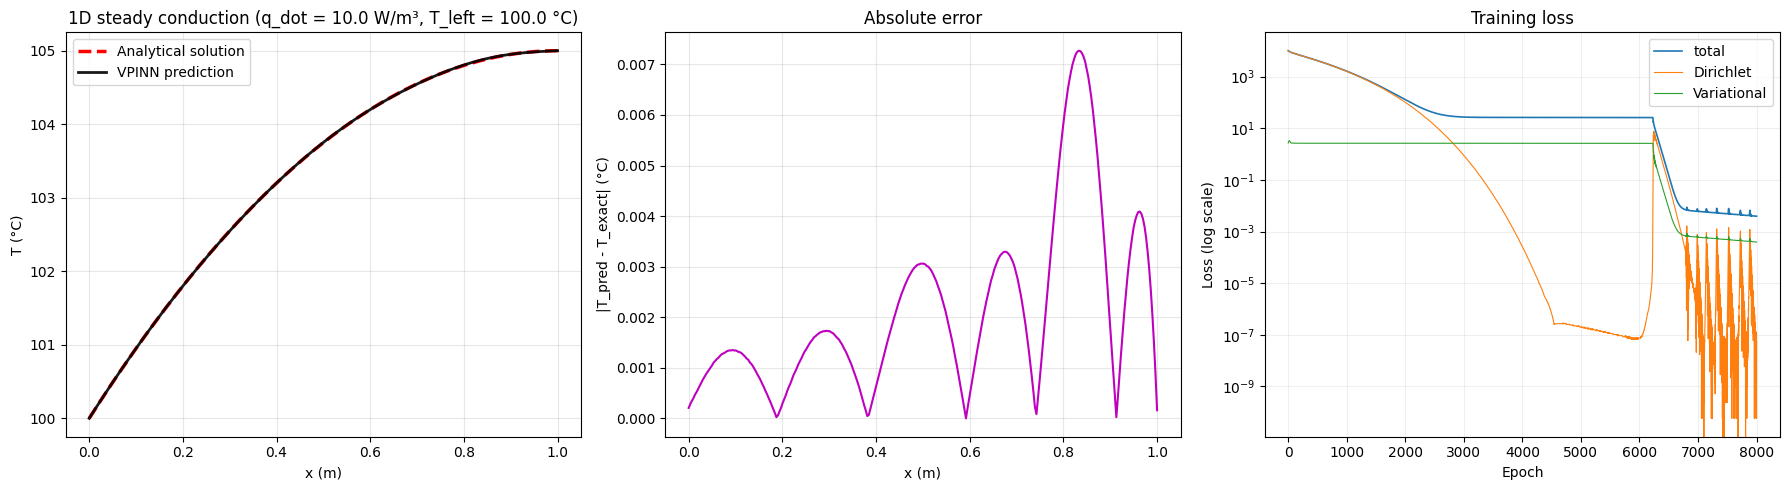

Max absolute error              : 7.2708e-03 °C
Relative L2 error (T)           : 2.6208e-05
Relative L2 error (T-T_left)    : 7.4180e-04
dT/dx at x=0  (pred / exact)    : +10.0190 / +10.0000 K/m
dT/dx at x=L  (pred / exact)    : +0.2216 / +0.0000 K/m
Heat flux at x=0 (pred / exact) : -10.0190 / -10.0000 W/m²


In [ ]:
with torch.no_grad():
    T_pred_vpinn = vpinn_T(x_test).cpu().numpy().ravel()

abs_error_vpinn = np.abs(T_pred_vpinn - T_ref)

max_err_vpinn = np.max(abs_error_vpinn)
rel_L2_vpinn = np.linalg.norm(T_pred_vpinn - T_ref) / np.linalg.norm(T_ref)
rel_L2_theta_vpinn = (
    np.linalg.norm(T_pred_vpinn - T_ref)
    / np.linalg.norm(T_ref - T_left)
)

x_ends_vpinn = torch.tensor(
    [[x_start], [x_end]],
    dtype=torch.float32,
    device=device,
    requires_grad=True
)

T_ends_vpinn = vpinn_T(x_ends_vpinn)

dTdx_ends_vpinn = torch.autograd.grad(
    T_ends_vpinn,
    x_ends_vpinn,
    torch.ones_like(T_ends_vpinn)
)[0].detach().cpu().numpy().ravel()

flux_left_vpinn = -k * dTdx_ends_vpinn[0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Temperature profile — same visual standard as PINN
axes[0].plot(x_exact, T_exact, "r--", lw=2.5, label="Analytical solution")
axes[0].plot(x_np, T_pred_vpinn, "k-", lw=2, alpha=0.9, label="VPINN prediction")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("T (°C)")
axes[0].set_title(f"1D steady conduction (q_dot = {q_dot} W/m³, T_left = {T_left} °C)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Absolute error — same visual standard as PINN
axes[1].plot(x_np, abs_error_vpinn, "m-", lw=1.5)
axes[1].set_xlabel("x (m)")
axes[1].set_ylabel("|T_pred - T_exact| (°C)")
axes[1].set_title("Absolute error")
axes[1].grid(True, alpha=0.3)

# Loss components — same visual standard as PINN
axes[2].semilogy(loss_history_vpinn["total"], lw=1.2, label="total")
axes[2].semilogy(loss_history_vpinn["dirichlet"], lw=0.8, label="Dirichlet")
axes[2].semilogy(loss_history_vpinn["variational"], lw=0.8, label="Variational")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss (log scale)")
axes[2].set_title("Training loss")
axes[2].legend()
axes[2].grid(True, which="both", alpha=0.2)

plt.tight_layout()
plt.show()

print(f"Max absolute error              : {max_err_vpinn:.4e} °C")
print(f"Relative L2 error (T)           : {rel_L2_vpinn:.4e}")
print(f"Relative L2 error (T-T_left)    : {rel_L2_theta_vpinn:.4e}")
print(f"dT/dx at x=0  (pred / exact)    : {dTdx_ends_vpinn[0]:+.4f} / {q_dot*L/k:+.4f} K/m")
print(f"dT/dx at x=L  (pred / exact)    : {dTdx_ends_vpinn[1]:+.4f} / {dTdx_right:+.4f} K/m")
print(f"Heat flux at x=0 (pred / exact) : {flux_left_vpinn:+.4f} / {-q_dot*L:+.4f} W/m²")

---
# 5. Comparação final - PINN vs VPINN

Os dois métodos usam:

- o mesmo problema físico;
- a mesma arquitetura neural;
- `Tanh`;
- `Adam`;
- `lr = 1e-3`;
- 8000 épocas;
- seed 123.

As diferenças estruturais são:

| Aspecto | PINN | VPINN |
|---|---|---|
| Formulação | Forte | Fraca |
| Física | Resíduo ponto a ponto | Resíduo integral ponderado |
| Pontos | 500 de colocação | 64 de quadratura |
| Derivada espacial máxima | Segunda | Primeira |
| Dirichlet | Penalidade | Penalidade |
| Neumann | Penalidade explícita | Natural na forma fraca |
| Informação física na loss | $r_{\mathrm{ODE}}(x_i)$ | $R_j$ para cada função teste |

**Importante:** as losses totais dos dois métodos não devem ser comparadas numericamente como se representassem a mesma quantidade. Elas são construídas a partir de resíduos matematicamente diferentes.

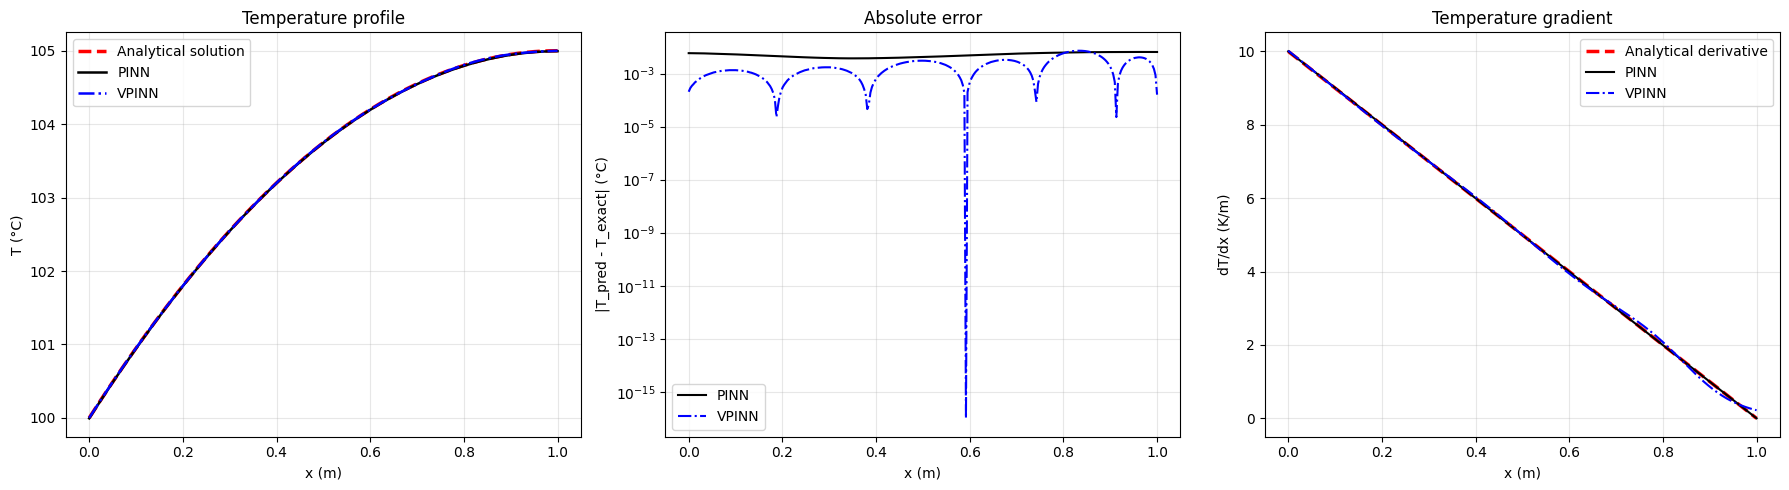

In [ ]:
# Derivative profiles for a physical comparison
x_grad_pinn = torch.linspace(
    x_start,
    x_end,
    300,
    device=device
).view(-1, 1)
x_grad_pinn.requires_grad_(True)

T_grad_pinn = pinn_T(x_grad_pinn)
dTdx_profile_pinn = torch.autograd.grad(
    T_grad_pinn,
    x_grad_pinn,
    torch.ones_like(T_grad_pinn)
)[0].detach().cpu().numpy().ravel()

x_grad_vpinn = torch.linspace(
    x_start,
    x_end,
    300,
    device=device
).view(-1, 1)
x_grad_vpinn.requires_grad_(True)

T_grad_vpinn = vpinn_T(x_grad_vpinn)
dTdx_profile_vpinn = torch.autograd.grad(
    T_grad_vpinn,
    x_grad_vpinn,
    torch.ones_like(T_grad_vpinn)
)[0].detach().cpu().numpy().ravel()

dTdx_ref = dTdx_exact_fn(x_np)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Temperature profile
axes[0].plot(x_np, T_ref, "r--", lw=2.5, label="Analytical solution")
axes[0].plot(x_np, T_pred_pinn, "k-", lw=1.8, label="PINN")
axes[0].plot(x_np, T_pred_vpinn, "b-.", lw=1.8, label="VPINN")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("T (°C)")
axes[0].set_title("Temperature profile")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Absolute error
axes[1].semilogy(x_np, abs_error_pinn + 1e-16, "k-", lw=1.5, label="PINN")
axes[1].semilogy(x_np, abs_error_vpinn + 1e-16, "b-.", lw=1.5, label="VPINN")
axes[1].set_xlabel("x (m)")
axes[1].set_ylabel("|T_pred - T_exact| (°C)")
axes[1].set_title("Absolute error")
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.3)

# Temperature gradient
axes[2].plot(x_np, dTdx_ref, "r--", lw=2.5, label="Analytical derivative")
axes[2].plot(x_np, dTdx_profile_pinn, "k-", lw=1.5, label="PINN")
axes[2].plot(x_np, dTdx_profile_vpinn, "b-.", lw=1.5, label="VPINN")
axes[2].set_xlabel("x (m)")
axes[2].set_ylabel("dT/dx (K/m)")
axes[2].set_title("Temperature gradient")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
print("=" * 108)
print(
    f"{'method':<10}"
    f"{'max error (°C)':>18}"
    f"{'L2 rel T':>14}"
    f"{'L2 rel T-Tleft':>18}"
    f"{'dTdx(0)':>13}"
    f"{'dTdx(L)':>13}"
    f"{'flux(0)':>13}"
    f"{'time (s)':>13}"
)
print("-" * 108)

print(
    f"{'Exact':<10}"
    f"{'-':>18}"
    f"{'-':>14}"
    f"{'-':>18}"
    f"{q_dot*L/k:>13.4f}"
    f"{0.0:>13.4f}"
    f"{-q_dot*L:>13.4f}"
    f"{'-':>13}"
)

print(
    f"{'PINN':<10}"
    f"{max_err_pinn:>18.4e}"
    f"{rel_L2_pinn:>14.4e}"
    f"{rel_L2_theta_pinn:>18.4e}"
    f"{dTdx_ends_pinn[0]:>13.4f}"
    f"{dTdx_ends_pinn[1]:>13.4f}"
    f"{flux_left_pinn:>13.4f}"
    f"{time_pinn:>13.2f}"
)

print(
    f"{'VPINN':<10}"
    f"{max_err_vpinn:>18.4e}"
    f"{rel_L2_vpinn:>14.4e}"
    f"{rel_L2_theta_vpinn:>18.4e}"
    f"{dTdx_ends_vpinn[0]:>13.4f}"
    f"{dTdx_ends_vpinn[1]:>13.4f}"
    f"{flux_left_vpinn:>13.4f}"
    f"{time_vpinn:>13.2f}"
)

print("=" * 108)

print()
print("Final training losses (NOT directly comparable across methods):")
print(f"  PINN  total loss : {loss_history_pinn['total'][-1]:.4e}")
print(f"  VPINN total loss : {loss_history_vpinn['total'][-1]:.4e}")

method        max error (°C)      L2 rel T    L2 rel T-Tleft      dTdx(0)      dTdx(L)      flux(0)     time (s)
------------------------------------------------------------------------------------------------------------
Exact                      -             -                 -      10.0000       0.0000     -10.0000            -
PINN              6.5308e-03    5.0235e-05        1.4218e-03      10.0029       0.0007     -10.0029        76.18
VPINN             7.2708e-03    2.6208e-05        7.4180e-04      10.0190       0.2216     -10.0190        20.46

Final training losses (NOT directly comparable across methods):
  PINN  total loss : 1.0526e-02
  VPINN total loss : 3.9117e-03


## 5.1 Como interpretar este primeiro benchmark


$$
\text{PINN}: \qquad r(x_i)\approx0
$$

versus

$$
\text{VPINN}: \qquad
R_j=
\int_0^L r(x)v_j(x)\,dx
\approx0.
$$

Além disso:

- a PINN usa duas diferenciações por autodiff para obter $\hat T''$;
- a VPINN usa uma diferenciação para obter $\hat T'$;
- a condição de Neumann é penalizada explicitamente na PINN;
- na VPINN ela aparece naturalmente após a integração por partes;
- a VPINN depende da escolha das funções teste e da quadratura;
- a PINN depende da distribuição dos pontos de colocação.

Este é apenas o **baseline didático**. Estudos posteriores poderão adicionar adimensionalização, outras famílias de funções teste, várias seeds, análise de custo por época, L-BFGS e estratégias de balanceamento.